<p>
    <b>ADA Facility report</b><br>
    <b>Gulbenkian Institute for Molecular Medicine</b><br>
    <b>Oeiras, PT</b>
</p>
<br>

# Setup

## Database Import

To make these sequences more "stable", we are working locally with reference files from the latest version of reference genome from *Mus musculus* provided by RefSeq (version 27).

* `.gtf`and `.fasta` file - https://www.ncbi.nlm.nih.gov/datasets/genome/GCF_000001635.27/


To work with the reference files from RefSeq genome annotation, the `pyranges` package are used (https://pyranges.readthedocs.io/en/latest/index.html).

----
*Correction from the last report*: Ensembl/GENCODE annotation was originally used for uniformity with the RNA-seq analysis. However, this annotation's automated pipeline selects the "Canonical" transcript based on maximal exon and isoform support, which for some genes includes rare upstream non-coding exons — pushing the annotated TSS thousands of bp upstream of the functional promoter (Frankish et al., 2015). This was identified while confirming Bach1's regulation of Nqo1 (https://pmc.ncbi.nlm.nih.gov/articles/PMC2804160/), a directly-regulated target gene: the Ensembl-anchored promoter window did not correspond to the published, experimentally-validated ARE/promoter region. RefSeq annotation was therefore used instead, as its curated transcripts are more conservative and better track experimentally-supported transcription start sites.

Supporting references:
*https://pubmed.ncbi.nlm.nih.gov/24564364/ - When conducting research that emphasizes reproducible and robust gene expression estimates, a less complex genome annotation may be preferred.*
*https://pubmed.ncbi.nlm.nih.gov/35354358/ - the use of the conservative RefSeq gene annotation yields better RNA-seq quantification results than the more comprehensive Ensembl annotation*
*https://pmc.ncbi.nlm.nih.gov/articles/PMC4502323/ - (Regarding Ensembl) However, differences between the gene sets in terms of CDS length, reading frame or especially the presence or absence of the CDS could increase false positive reports, thus complicating interpretation.*
 

In [1]:
#| label: setup_packages_paths
#| code-fold: true
#| code-summary: "Setup: Imports and Reference File Paths"
#| output: false
import pyranges as pr
import pyfaidx
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import os
import session_info

# -------- Setting the Path for the necessary files -------- #

GTF_v27 = "/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Data/ncbi_dataset_RefSeq_GCF_000001635.27/genomic.gff"
FA_v27  = "/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Data/ncbi_dataset_RefSeq_GCF_000001635.27/GCF_000001635.27_GRCm39_genomic.fna"


In [2]:
#| label: gtf_import
#| code-fold: true
#| code-summary: "Import and Filter Reference GTF"
#| output: false
# -------- Reference GTF -------- #
gtf = pr.read_gff3(GTF_v27)                           # Import the GTF file, which has all the information necessary to extract the coordinates. Keep all attributes in single string
gtf_canonical = gtf[(gtf.Feature == "mRNA") & 
                     gtf.tag.str.contains("RefSeq Select", na=False)] 
   # Filter to include only transcripts that contain the tag "RefSeq Select" (curated to canonical transcripts)

## Promotor Gene Retrieval

A list of genes was given by the user to check for transcription factors motifs in the promotor:

Transcription Factor genes: *Nfe2l2, SpiC, Bach1*
Regulation Network of SpiC: *Blvra, Hmox1, Vcam1, Slc40a1, Nqo1, Gsr, Slc7a11, Gclc, Cat, Gpx4, Gclm, Gss, Txnrd1, Fth1, Nfs1, Cisd1, Aifm2, Acsl4, Acsl2, LPCAT3, G6PDX, PGD, ME1, IDH1, Nox1, Elovl7, Ido1, ALAS1, DHODH, ACSL3, SCD1, *SCD5*.
Control gene of Bach1: *Nqo1*

A few genes were found under other name in the genome used in this work:
- Acsl2 was found by the Acsl1 synonym name (https://www.uniprot.org/uniprotkb/P41216/entry);
- Aifm2 is the gene name of Fsp1 which wasn't found, and therefore not considered (https://www.uniprot.org/uniprotkb/Q8BUE4/entry);
- There was no correspondence found for SCD5 in mice in this genome, nor in uniprot.

The promoter region for each gene was defined as **−2,000 bp to +200 bp relative to the transcription start site (TSS)** of the canonical transcript. This interval was selected because it encompasses the proximal regulatory regions where transcription factor binding is most frequently observed.

More specifically:

- The **−2,000 bp upstream region** captures the proximal promoter and many of the cis-regulatory transcription factor binding sites.
- The **+200 bp downstream region** includes the TSS-proximal sequence, which often contains core promoter elements and regulatory motifs that overlap the transcription start site.
- The **TSS of the canonical transcript** was used as the reference coordinate to ensure a consistent and standardized definition of promoter regions across all analyzed genes.

These promoter sequences were subsequently used for transcription factor binding site analysis to evaluate the potential for direct SpiC-mediated transcriptional regulation, or indirect regulation through Nfe2l2-mediated transcriptional regulation.

### Extract transcript coordinates

In [3]:
#| label: gene_subset
#| code-fold: true
#| code-summary: "Select Canonical Transcripts for Genes of Interest"
#| output: false
# List of genes of interest

#the gene name needs to be have a format with the first letter only in Caps to be found
genes = ["Spic", "Nfe2l2", "Bach1", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1", "Scd5", "Nqo1", "Hmox1"]             

# NCBI RefSeq GFF3 uses "gene", not "gene_name" -- confirm via gtf_canonical.columns.tolist()
# before trusting this line if it comes back empty.
gtf_sub = gtf_canonical[gtf_canonical.gene.isin(genes)]
 
found = set(gtf_sub.df["gene"])
missing = set(genes) - found
 
print(f"{len(found)}/{len(set(genes))} genes found")
if missing:
    print("Missing:", sorted(missing))
 
print(f"Are there duplicated values: {gtf_sub.df['gene'].duplicated().any()}")              

34/35 genes found
Missing: ['Scd5']
Are there duplicated values: False


Register the Start & End coordinates

In [4]:
#| label: gtf_sub_preview
#| code-fold: true
#| code-summary: "Selected Transcript Coordinates"
#| output: asis
gtf_sub[['Chromosome', 'gene', 'transcript_id', 'Source', 'Feature', 'Start', 'End', 'Strand']]    # Inspect the selected canonical transcripts (one per gene of interest)

/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,gene,transcript_id,Start,End,Strand,Source,Feature
0,NC_000067.7,Acsl3,NM_001033606.3,78635599,78685462,+,BestRefSeq,mRNA
1,NC_000067.7,Slc40a1,NM_016917.2,45947229,45964754,-,BestRefSeq,mRNA
2,NC_000067.7,Idh1,NM_010497.3,65197774,65218301,-,BestRefSeq,mRNA
3,NC_000068.8,Blvra,NM_026678.4,126912576,126939004,+,BestRefSeq,mRNA
4,NC_000068.8,Nfe2l2,NM_010902.5,75505859,75534860,-,BestRefSeq,mRNA
5,NC_000068.8,Cat,NM_009804.2,103284248,103315498,-,BestRefSeq,mRNA
6,NC_000068.8,Gss,NM_008180.2,155405100,155434730,-,BestRefSeq,mRNA
7,NC_000068.8,Nfs1,NM_010911.3,155965568,155986106,-,BestRefSeq,mRNA
8,NC_000069.7,Gclm,NM_008129.4,122039205,122060864,+,BestRefSeq,mRNA
9,NC_000069.7,Slc7a11,NM_011990.2,50319384,50398062,-,BestRefSeq,mRNA


Plus strand (+): transcription goes left→right along the reference. The biological start (TSS, 5′ end) is at Start, and the 3′ end is at End.
Minus strand (-): transcription goes right→left along the reference. The biological start (TSS, 5′ end) is at End, and the 3′ end is at Start.

### Extract promoter coordinates

Register the Start & End coordinates. 

* In the *strand -* the TSS is at the `End` coordinate of the transcript. Therefore the start of the promoter should be +2000bp from `End` in `gtf_sub`/transcript (Start of the promoter is in the `End` coordinate of the promoter),  and -200bp (End of the promoter is in the `Start` coordinate of the promoter). 

* In the *strand +* the TSS is at the `Start` coordinate of the transcript. Therefore the promoter should `Start` -2000bp from `Start` in `gtf_sub`/transcript (Start of the promoter is in the `Start` coordinate of the promoter),  and  -200bp (End of the promoter is in the `End` coordinate of the promoter). 



In [5]:
#| label: promoter_coords
#| code-fold: true
#| code-summary: "Compute 2 kb Promoter Coordinates"
#| output: false

# five_end(): collapses each interval to its single TSS coordinate (strand-aware --
#             gene Start on +, gene End on -), giving a 1bp interval at the TSS.
# .slack({"5": 2000, "3": 200}): extends that TSS point strand-aware:
#             2000bp toward the 5' side (upstream) and 200bp toward the 3' side
#             (downstream), so the result is your -2000/+200 promoter window
#             regardless of which genomic strand the gene is on.
prom_2kb = gtf_sub.five_end().slack({"5": 2000, "3": 200}) 
prom_2kb[['gene','transcript_id','Start', 'End', 'Strand']]                            

/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,Start,End,Strand,gene,transcript_id
0,NC_000067.7,78633599,78635800,+,Acsl3,NM_001033606.3
1,NC_000067.7,45964553,45966754,-,Slc40a1,NM_016917.2
2,NC_000067.7,65218100,65220301,-,Idh1,NM_010497.3
3,NC_000068.8,126910576,126912777,+,Blvra,NM_026678.4
4,NC_000068.8,75534659,75536860,-,Nfe2l2,NM_010902.5
5,NC_000068.8,103315297,103317498,-,Cat,NM_009804.2
6,NC_000068.8,155434529,155436730,-,Gss,NM_008180.2
7,NC_000068.8,155985905,155988106,-,Nfs1,NM_010911.3
8,NC_000069.7,122037205,122039406,+,Gclm,NM_008129.4
9,NC_000069.7,50397861,50400062,-,Slc7a11,NM_011990.2


## Extract sequences based on the coordinates

In [6]:
#| label: extract_sequences
#| code-fold: true
#| code-summary: "Extract Promoter Sequences from Reference"
#| output: false

seqs_2kb = pr.get_sequence(prom_2kb, path=FA_v27)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

df_2kb                 = seqs_2kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_2kb["Gene_Name"]    = prom_2kb.df['gene']                 # Attach gene names for use in the FASTA headers
df_2kb["TranscriptID"] = prom_2kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/promoters_sequences.fasta", "w") as file:
    for index, row in df_2kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

## Retrieve Transcription Factors Motifs

Position-specific scoring matrices were taken from the **CIS-BP** *Mus musculus*
collection (Build 3.10, https://cisbp.ccbr.utoronto.ca), downloaded in bulk and
stored under `Data/`. 

CIS-BP holds several motifs per factor and they differ in information content,
so the choice matters: for SpiC, `M01570_3.10` is close to uniform at most
positions and would return many weakly-supported matches, while `M03009_3.10`
resolves a clear ETS-family site. The accessions retained are listed explicitly
in `MOTIFS` below, so the report records which matrices were scanned.

The bulk download stores each matrix as position-wise probabilities. These are
multiplied by 100, matching the scale RSAT uses in its own CIS-BP files, so that
the pseudo-count of 1 applied by *matrix-scan* remains a small correction rather
than a substantial fraction of each column.

In [7]:
#| label: rsat_setup
#| code-fold: true
#| code-summary: "Setup: paths and scan parameters"
#| output: false
 
import os, re, subprocess
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 
# paths and variables
 
PROJECT  = Path("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder")
RESULTS  = PROJECT / "Results"
SCAN_DIR = RESULTS / "matrix_scan"
SCAN_DIR.mkdir(parents=True, exist_ok=True)
RSAT_ENV = Path("/srv/ext_home/ssalazar/.conda/envs/rsat")
 
MARKOV_ORDER = 1        # background order; oligo length k = order + 1
PVAL         = 1e-4
TSS_OFFSET   = 201      # -origin end places the TSS at -201
 
# rsat is a Perl script: its env's bin must lead PATH, or the shebang picks base's perl
ENV = os.environ | {"PATH": f"{RSAT_ENV / 'bin'}{os.pathsep}{os.environ['PATH']}",
                     "RSAT": str(RSAT_ENV / 'share' / 'rsat'),
                     "CONDA_PREFIX": str(RSAT_ENV)}
 
 
def rsat(tool, *args):
    # some tools report errors on stdout while exiting 0
    cmd = [str(RSAT_ENV / "bin" / "rsat"), tool, *map(str, args)]
    p = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    out = p.stderr + p.stdout
    if p.returncode or re.search(r"^Error", out, re.M):
        raise RuntimeError(" ".join(cmd) + "\n" + out)
    return out
 
 
def read_fasta(path):
    # [(header, sequence), ...], headers keep their '>'
    # used for counting/subsetting only, so no Biopython dependency;
    # `cur is not None` (not `cur`) so a header right after another header
    # doesn't swallow the next record's lines
    recs, cur = [], None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            cur = [line, []]
            recs.append(cur)
        elif cur is not None:
            cur[1].append(line.strip())
    return [(h, "".join(s)) for h, s in recs]
 
 

In [ ]:
#| label: tf_matrices
#| code-fold: true
#| code-summary: "transcription factor matrices"
#| output: false
 
CISBP = PROJECT / "Data" / "Mus_musculus_2026_09_17_11_49_am_CISBP"
 
# motif accession -> name to use in the ft_name column of the scan
# looked up once in TF_Information.txt, then hard-coded here
MOTIFS = {"M03221_3.10": "Spic",
          "M09222_3.10": "Nfe2l2_1",
          "M10174_3.10": "Nfe2l2_2",
          "M10181_3.10": "Bach1"}
 
# color dictionary for consistency across plots (npg / Nature Publishing Group palette)
MOTIF_COLORS = {"Spic":     "#E64B35",
                 "Nfe2l2_1": "#4DBBD5",
                 "Nfe2l2_2": "#00A087",
                 "Bach1":    "#3C5488"}
 
blocks = []


for acc, label in MOTIFS.items():
    m = pd.read_csv(CISBP / {acc}.txt", sep="\t")

    
    from PIL import Image

    import matplotlib.pyplot as plt

    # Open images
    ifw = Image.open(CISBP / f"logos_all_motifs/{acc}_fwd.png")
    irev = Image.open(CISBP / f"logos_all_motifs/{acc}_rev.png")

    # Display side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(ifw)
    axes[0].set_title("Forward motif")
    axes[0].axis("off")

    axes[1].imshow(irev)
    axes[1].set_title("Reverse motif")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()
    # CIS-BP gives probabilities (rows sum to 1); x100 makes them count-like, so
    # matrix-scan's -pseudo 1 stays a small correction instead of half the column
    rows = [f"{i:02d}\t" + "\t".join(f"{v * 100:.4f}" for v in r)
            for i, r in enumerate(m[["A", "C", "G", "T"]].values, start=1)]
 
    blocks.append(f"AC  {acc}\nXX\nID  {label}\nXX\nDE  {label}\n"
                   "P0\tA\tC\tG\tT\n" + "\n".join(rows) + "\nXX\n//\n")
    print(f"  {acc:<14} {len(m)} bp -> {label}")
 
MATRIX = SCAN_DIR / "motif_matrices_SpiC_Nfe2l2_Bach1.tf"
MATRIX.write_text("".join(blocks))
print(f"\n{len(blocks)} matrices saved in {MATRIX.name}")

  M03221_3.10    14 bp -> Spic
  M09222_3.10    11 bp -> Nfe2l2_1
  M10174_3.10    14 bp -> Nfe2l2_2
  M10181_3.10    14 bp -> Bach1

4 matrices saved in motif_matrices_SpiC_Nfe2l2_Bach1.tf


# Search of Motifs in the Promoter Regions

Motif scanning was performed with the **Regulatory Sequence Analysis Tools (RSAT)** suite to assess the presence of **SpiC**, **Nfe2l2** and **Bach1** transcription factor binding motifs within the retrieved promoter sequences. Detection of these motifs provides preliminary evidence for potential direct regulatory interactions between the transcription factors and their target genes.

The scan is executed from this notebook against a local RSAT installation (`rsat-core`, bioconda), replacing the earlier manual Web-form procedure described in **SOP RSAT Tools - Part 2**. Running it here means the matrices, background model and thresholds are recorded in the report itself rather than in screenshots.

Position-specific scoring matrices were taken from the **CIS-BP** *Mus musculus* collection distributed with RSAT (`motif_databases`, CIS-BP 2.00). The background model is a **first-order Markov chain estimated from the input promoter set**: because a PSSM treats positions independently, dinucleotide composition is accounted for solely in the background term, and the SpiC motif consists largely of purine-purine steps that are over-represented in mouse genomic sequence. An order-0 model would not represent this and would assign such matches anticonservative *P*-values.

In [40]:
#| label: rsat_scan
#| code-fold: true
#| code-summary: "Background model and matrix-scan"
#| output: false
 
import tempfile
 
def scan(motifs, genes=None, pval=PVAL, name=None):
    # motifs: list of ft_name labels, e.g. ['Spic', 'Bach1']
    # genes: list of gene names; None scans all promoters
    # only the .ft.txt is kept
    FASTA = RESULTS / "promoters_sequences.fasta"
    out = SCAN_DIR / f"scanmotif_{name}.ft"
 
    # matrix subset, promoter subset and background model are RSAT inputs, so they're
    # written to a temp dir removed on return; still recoverable from the ';' header of
    # the .ft.txt, which records the matrix, pseudo-counts and residue probabilities
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
 
        # requested matrices only, from motif_matrices_SpiC_Nfe2l2_Bach1.tf
        blocks = [b.strip() + "\n//\n" for b in MATRIX.read_text().split("//")
                  if (m := re.search(r"^ID\s+(\S+)\s*$", b, re.M))
                  and m.group(1) in motifs]
        assert len(blocks) == len(motifs), f"matrix not found, wanted {motifs}"
        mat = tmp / "matrices.tf"
        mat.write_text("".join(blocks))
 
        # requested promoters only; genes=None keeps all
        recs = [(i, s) for i, s in read_fasta(FASTA)
                if not genes or any(g.lower() in i.lower() for g in genes)]
        assert recs, f"no promoter matched {genes}"
        seqs = tmp / "promoters.fasta"
        seqs.write_text("".join(f">{i}\n{s}\n" for i, s in recs))
 
        # background is always estimated from the FULL promoter set, never the gene
        # subset: an order-1 model fit to one or two promoters is too sparse to be
        # stable, and its p-values wouldn't be comparable across subsets.
        # -bginput / create-background-model fail in this build (rsat-core 2025.04.04,
        # bioconda) at every Markov order ("the sum must be strictly positive", then a
        # division by zero in RSAT/matrix.pm), so the model is estimated with
        # oligo-analysis and passed via -bgfile instead: same estimator, same sequences.
        # -1str matches the web run, whose residue probabilities are strand-asymmetric.
        # verified against the web run: 62/63 sites, same 20 promoters, marginals to 3 decimals
        bg = tmp / "bg.tab"
        rsat("oligo-analysis", "-i", FASTA, "-l", MARKOV_ORDER + 1, "-1str",
             "-return", "occ,freq", "-o", bg)
        assert bg.stat().st_size, f"empty background model: {bg}"
 
        # -origin end keeps positions negative from the sequence end (TSS at -TSS_OFFSET)
        # -2str reports D/R, combined with transcript strand downstream
        # -return limits gives the START_END rows used for promoter extents
        rsat("matrix-scan", "-v", 1,
             "-i", seqs, "-seq_format", "fasta",
             "-m", mat, "-matrix_format", "transfac",
             "-bgfile", bg, "-bg_pseudo", 0.01, "-pseudo", 1,
             "-2str", "-origin", "end", "-n", "score",
             "-return", "limits", "-return", "sites", "-return", "pval",
             "-uth", "pval", pval, "-o", out)
 
    hits = pd.read_csv(out, sep="\t", comment=";").query("ft_type == 'site'")
    hits.attrs["scan_path"] = out
    print(f"{len(recs)} promoters, {len(motifs)} matrices, "
          f"{len(hits)} sites at P < {pval:g}")
    return hits

In [41]:
#| label: fig-sitemap
#| fig-cap: "matrix-scan sites across the SpiC network promoters, positions relative to TSS. Marker size scales with significance; triangles point up for motifs on the direct strand, down for reverse."
#| output: true

def sitemap(hits, name=None, pval=PVAL):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    """
    
    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=80 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name}.svg"
    fig.savefig(fig_path)
  
    return fig

## SpiC Motifs in the SpiC Network Genes Promotores

30 promoters, 1 matrices, 24 sites at P < 0.0001


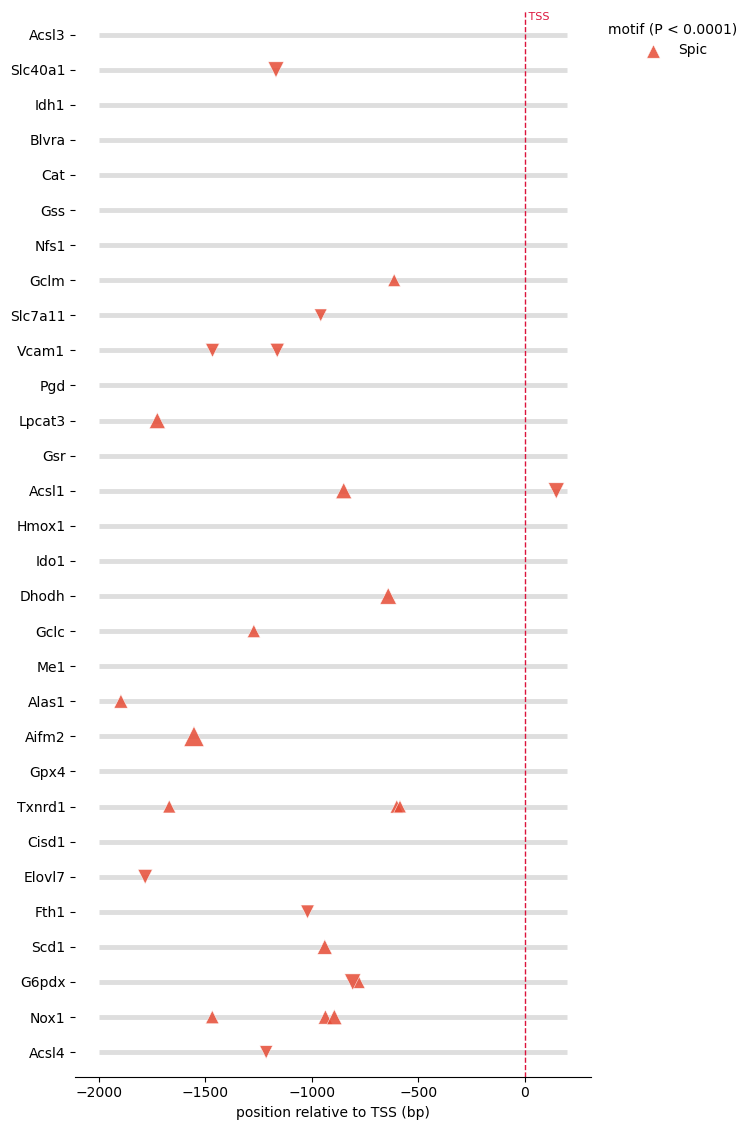

In [42]:

hits_SpiCnet_SpiCmotif = scan(["Spic"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiCnetwork_SpiCmotif')             

graph_SpiCnet_SpiCmotif = sitemap(hits_SpiCnet_SpiCmotif, name='SpiCnetwork_SpiCmotif')

In [43]:
#| label: rsat_spic_load
#| code-fold: true
#| code-summary: "Load and Clean RSAT Motif Hits (SpiC Network)"
#| output: false

def process_motif_hits(name, hits_df, gtf_sub):

        # prepare data from RSAT tools
        sites = hits_df[hits_df["ft_type"] == "site"].copy()   # drop the 'limit' (START_END) rows, not significant
        sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id = Gene_Name|TranscriptID
        sites["Gene_Name"] = sites["Gene_Name"].str.strip('>')

        sites_filtered = sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
        sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                        'start':   "start_motif_pos_promotor",   # 1-based TSS base
                                                        'end':     "end_motif_pos_promotor",
                                                        'strand':  "strand_motif"})

        # get transcript metadata + TSS (from five_end(), 1-based, strand dependent), merge in one go
        meta = (gtf_sub.df[["Chromosome", "gene", "Strand", "transcript_id"]]
                .rename(columns={"Strand": "Chromosome_Strand", "transcript_id": "TranscriptID"})
                .merge(gtf_sub.five_end().df[["transcript_id", "End"]]
                        .rename(columns={"End": "TSS_chromossomal_localization", "transcript_id": "TranscriptID"}),
                        on="TranscriptID", how="left"))

        sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

        # transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)
        sites_filtered["start_motif_pos_promotor"] += 201
        sites_filtered["end_motif_pos_promotor"]   += 201

        # nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
        sites_filtered["dist_to_TSS"] = np.where(
        sites_filtered["end_motif_pos_promotor"] < 0, sites_filtered["end_motif_pos_promotor"],
        np.where(sites_filtered["start_motif_pos_promotor"] > 0, sites_filtered["start_motif_pos_promotor"], 0),
        )

        # to genome (1-based): + adds, - subtracts (edges swap so start <= end)
        plus = sites_filtered["Chromosome_Strand"].eq("+")
        TSS  = sites_filtered["TSS_chromossomal_localization"]
        start = np.where(plus, TSS + sites_filtered["start_motif_pos_promotor"], TSS - sites_filtered["end_motif_pos_promotor"])
        end   = np.where(plus, TSS + sites_filtered["end_motif_pos_promotor"],   TSS - sites_filtered["start_motif_pos_promotor"])

        sites_filtered["motif_genomic_localization"] = start.astype(int).astype(str) + "-" + end.astype(int).astype(str)
        sites_filtered["motif_genomic_strand"] = np.where(plus == sites_filtered["strand_motif"].eq("D"), "+", "-")

        sites_filtered.drop(columns=["strand_motif"], inplace=True)

        sites_filtered.to_csv(
        f"/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/motifs_coordinates_{name}.csv",
        index=False,
        )
        return sites_filtered

In [44]:
#| label: spicnetwork_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Motif Coordinates"
#| output: asis

spic_network_motifs_table = process_motif_hits("SpiC_network", hits_SpiCnet_SpiCmotif, gtf_sub)
spic_network_motifs_table   # Inspect the SpiC-network motif hits mapped to genomic coordinates


,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promotor,end_motif_pos_promotor,Pval,sig,Chromosome,gene,Chromosome_Strand,TSS_chromossomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Slc40a1,NM_016917.2,AAAATGGGGTAGTA,-1174,-1161,0.000020,4.694,NC_000067.7,Slc40a1,-,45964754,-1161,45965915-45965928,+
1,Gclm,NM_008129.4,GGAATGGGGAAGAA,-619,-606,0.000093,4.030,NC_000069.7,Gclm,+,122039206,-606,122038587-122038600,+
2,Slc7a11,NM_011990.2,CAAAGCCGGAAATT,-964,-951,0.000093,4.030,NC_000069.7,Slc7a11,-,50398062,-951,50399013-50399026,+
3,Vcam1,NM_011693.3,CAACAGAGGAAGTG,-1472,-1459,0.000054,4.271,NC_000069.7,Vcam1,-,115923337,-1459,115924796-115924809,+
4,Vcam1,NM_011693.3,ATAAAAGGGAAGTT,-1168,-1155,0.000045,4.343,NC_000069.7,Vcam1,-,115923337,-1155,115924492-115924505,+
5,Lpcat3,NM_145130.3,AGCATGAGGAAGTA,-1731,-1718,0.000017,4.780,NC_000072.7,Lpcat3,+,124640091,-1718,124638360-124638373,+
6,Acsl1,NM_007981.5,ATATTGCGGAAGTC,-856,-843,0.000017,4.780,NC_000074.7,Acsl1,+,46924214,-843,46923358-46923371,+
7,Acsl1,NM_007981.5,GAAAAGCGGAACGT,142,155,0.000018,4.750,NC_000074.7,Acsl1,+,46924214,142,46924356-46924369,-
8,Dhodh,NM_020046.3,AAAGTGGGGAAGTA,-647,-634,0.000013,4.873,NC_000074.7,Dhodh,-,110335305,-634,110335939-110335952,-
9,Gclc,NM_010295.2,CAAATGTGGAAGTC,-1278,-1265,0.000080,4.099,NC_000075.7,Gclc,+,77661817,-1265,77660539-77660552,+


## Analysis of Transcription Factors Cross regulation

### Nfe2l2 Regulation

30 promoters, 2 matrices, 44 sites at P < 0.0001


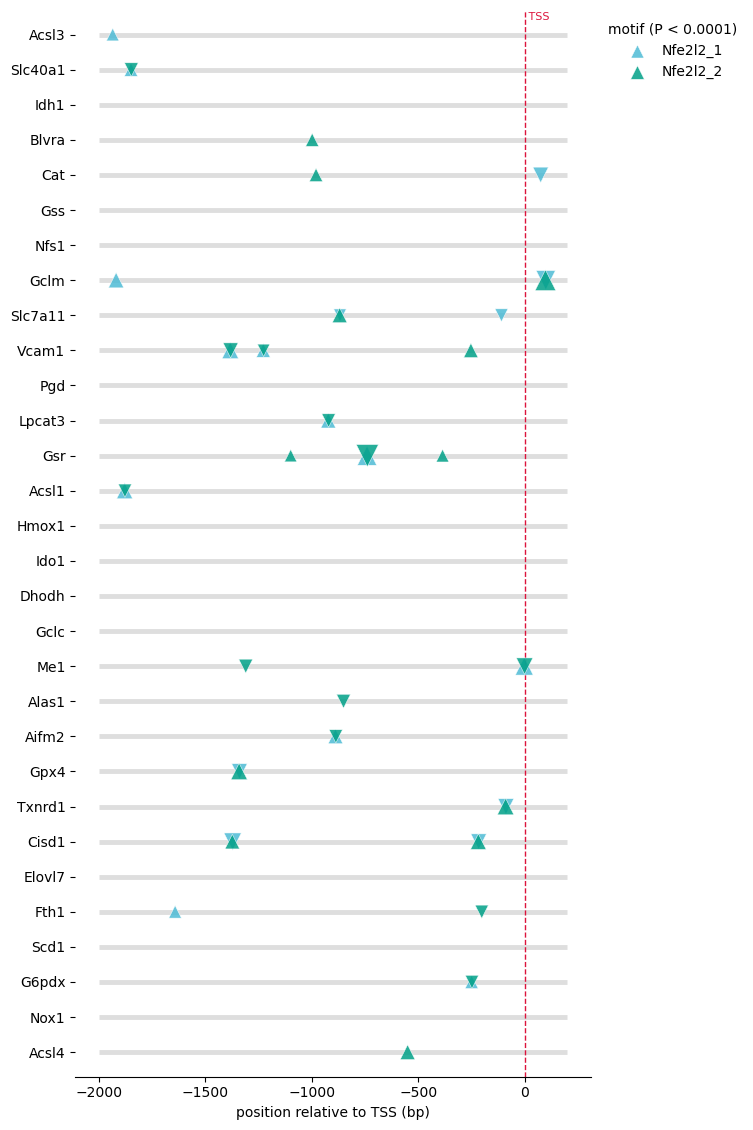

In [45]:

#| label: spicnetwork_Nfe2l2_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network Nfe2l2 Motifs Map"
#| output: asis

hits_SpiCnet_Bach1motif = scan(["Nfe2l2_1", "Nfe2l2_2"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_Bach1motif')             

graph_SpiCnet_Bach1motif = sitemap(hits_SpiCnet_Bach1motif, name="SpiC_network_Bach1motif")

In [46]:
#| label: spicnetwork_Nfe2l2_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Nfe2l2 Motifs Table"
#| output: asis

spic_network_Nfe2l2motif_table = process_motif_hits("SpiC_network_Nfe2l2Motif", hits_SpiCnet_nfe2l2_motif, gtf_sub)
spic_network_Nfe2l2motif_table  

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promotor,end_motif_pos_promotor,Pval,sig,Chromosome,gene,Chromosome_Strand,TSS_chromossomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,6.300000e-05,4.201,NC_000067.7,Acsl3,+,78635600,138,78635738-78635751,+
1,Slc40a1,NM_016917.2,TGCTCTCTCAAGCT,-45,-32,6.300000e-05,4.201,NC_000067.7,Slc40a1,-,45964754,-32,45964786-45964799,-
2,Cat,NM_009804.2,TGCTGTCTCACGTT,70,83,8.800000e-07,6.055,NC_000068.8,Cat,-,103315498,70,103315415-103315428,-
3,Gclm,NM_008129.4,TGCTTAGTCATTGT,94,107,5.500000e-06,5.257,NC_000069.7,Gclm,+,122039206,94,122039300-122039313,+
4,Slc7a11,NM_011990.2,AGCTGAGTAATGTT,-114,-101,1.400000e-05,4.857,NC_000069.7,Slc7a11,-,50398062,-101,50398163-50398176,-
5,Slc7a11,NM_011990.2,CGCTTTCTCAAGCT,-98,-85,6.600000e-05,4.182,NC_000069.7,Slc7a11,-,50398062,-85,50398147-50398160,-
6,Vcam1,NM_011693.3,TACTGACTCACATT,-256,-243,3.000000e-06,5.518,NC_000069.7,Vcam1,-,115923337,-243,115923580-115923593,-
7,Gsr,NM_010344.4,CACCGAGTTAAAGT,-564,-551,1.000000e-04,3.999,NC_000074.7,Gsr,+,34143266,-551,34142702-34142715,-
8,Hmox1,NM_010442.2,TGCTCGCTCACGGT,-5,8,5.100000e-05,4.291,NC_000074.7,Hmox1,+,75820246,0,75820241-75820254,+
9,Dhodh,NM_020046.3,TACTGAGTAAAACT,-1796,-1783,5.300000e-05,4.272,NC_000074.7,Dhodh,-,110335305,-1783,110337088-110337101,+


### Bach1 Regulation

#### Bach1 Regulation of SpiC network

30 promoters, 1 matrices, 18 sites at P < 0.0001


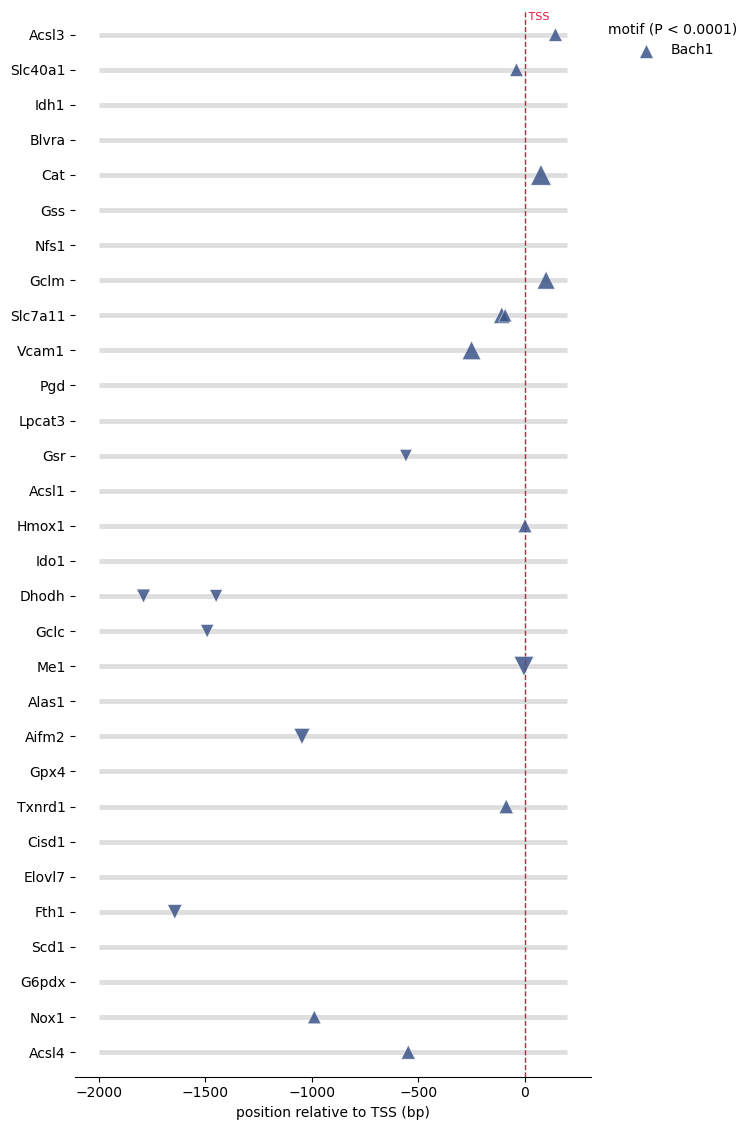

In [47]:
#| label: spicnetwork_Bach1_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network Bach1 Motifs Map"
#| output: asis

hits_SpiCnet_bach1_motif = scan(["Bach1"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_Nfe2l2motif')             

graph_SpiCnet_bach1_motif = sitemap(hits_SpiCnet_bach1_motif, name="SpiC_network_Bach1motif")

In [48]:
#| label: spicnetwork_Nfe2l2_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Nfe2l2 Motifs Table"
#| output: asis

spic_network_Nfe2l2motif_table = process_motif_hits("SpiC_network_Nfe2l2Motif", hits_SpiCnet_nfe2l2_motif, gtf_sub)
spic_network_Nfe2l2motif_table  

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promotor,end_motif_pos_promotor,Pval,sig,Chromosome,gene,Chromosome_Strand,TSS_chromossomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,6.300000e-05,4.201,NC_000067.7,Acsl3,+,78635600,138,78635738-78635751,+
1,Slc40a1,NM_016917.2,TGCTCTCTCAAGCT,-45,-32,6.300000e-05,4.201,NC_000067.7,Slc40a1,-,45964754,-32,45964786-45964799,-
2,Cat,NM_009804.2,TGCTGTCTCACGTT,70,83,8.800000e-07,6.055,NC_000068.8,Cat,-,103315498,70,103315415-103315428,-
3,Gclm,NM_008129.4,TGCTTAGTCATTGT,94,107,5.500000e-06,5.257,NC_000069.7,Gclm,+,122039206,94,122039300-122039313,+
4,Slc7a11,NM_011990.2,AGCTGAGTAATGTT,-114,-101,1.400000e-05,4.857,NC_000069.7,Slc7a11,-,50398062,-101,50398163-50398176,-
5,Slc7a11,NM_011990.2,CGCTTTCTCAAGCT,-98,-85,6.600000e-05,4.182,NC_000069.7,Slc7a11,-,50398062,-85,50398147-50398160,-
6,Vcam1,NM_011693.3,TACTGACTCACATT,-256,-243,3.000000e-06,5.518,NC_000069.7,Vcam1,-,115923337,-243,115923580-115923593,-
7,Gsr,NM_010344.4,CACCGAGTTAAAGT,-564,-551,1.000000e-04,3.999,NC_000074.7,Gsr,+,34143266,-551,34142702-34142715,-
8,Hmox1,NM_010442.2,TGCTCGCTCACGGT,-5,8,5.100000e-05,4.291,NC_000074.7,Hmox1,+,75820246,0,75820241-75820254,+
9,Dhodh,NM_020046.3,TACTGAGTAAAACT,-1796,-1783,5.300000e-05,4.272,NC_000074.7,Dhodh,-,110335305,-1783,110337088-110337101,+


#### Bach1 Regulation of SpiC and Nfe2l2, Nqo1 and Hmox1 as reference

5 promoters, 1 matrices, 2 sites at P < 0.0001


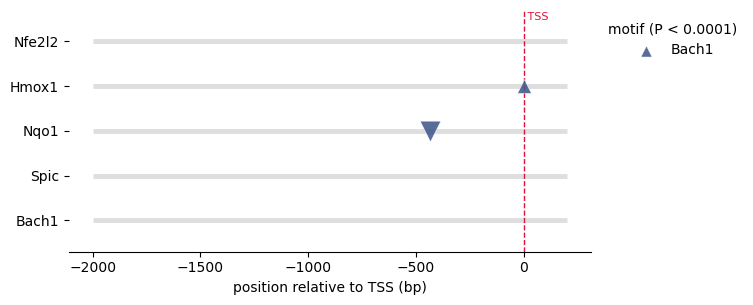

In [49]:
#| label: FT_crossregulation_motifs_table
#| code-fold: true
#| code-summary: "SpiC, Nfe2l2 and Bach1 Cross Regulation Motifs Map"
#| output: asis

hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = scan(["Bach1"], genes=["Spic", "Nfe2l2", "Bach1", "Hmox1", "Nqo1"])             

graph_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif)

### All Transcription Factors

#### SpiC, Nfe2l2, Bach1 Cross Regulation 

3 promoters, 4 matrices, 7 sites at P < 0.0001


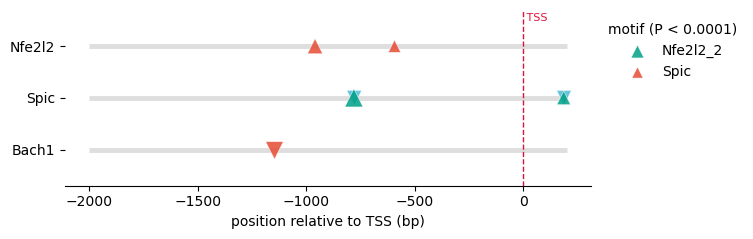

In [50]:
#| label: FT_crossregulation_motifs_map
#| code-fold: true
#| code-summary: "SpiC, Nfe2l2 and Bach1 Cross Regulation Motifs Map"
#| output: asis

hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic", "Nfe2l2", "Bach1"], name="TF_crossregulation_spic_nfel2l_bach1")             

graph_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif)

In [51]:
#| label: FT_crossregulation_motifs_table
#| code-fold: true
#| code-summary: "SpiC, Nfe2l2 and Bach1 Cross Regulation Motifs Table"
#| output: asis

spic_network_alltfs_motifs_table = process_motif_hits("TF_crossregulation_spic_nfel2l_bach1", hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif, gtf_sub)
spic_network_alltfs_motifs_table  

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promotor,end_motif_pos_promotor,Pval,sig,Chromosome,gene,Chromosome_Strand,TSS_chromossomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Nfe2l2,NM_010902.5,AAATAGAGTAAGTA,-966,-953,0.000025,4.609,NC_000068.8,Nfe2l2,-,75534860,-953,75535813-75535826,-
1,Nfe2l2,NM_010902.5,CAAATCAGGGAGTG,-600,-587,0.000098,4.008,NC_000068.8,Nfe2l2,-,75534860,-587,75535447-75535460,-
2,Spic,NM_011461.3,AACTTCTGAGTCAT,-787,-774,0.000004,5.379,NC_000076.7,Spic,-,88518885,-774,88519659-88519672,-
3,Spic,NM_011461.3,ATGACTCAGAA,-784,-774,0.000028,4.551,NC_000076.7,Spic,-,88518885,-774,88519659-88519669,+
4,Spic,NM_011461.3,TAAAGCTGAATCAT,179,192,0.000054,4.270,NC_000076.7,Spic,-,88518885,179,88518693-88518706,-
5,Spic,NM_011461.3,ATGATTCAGCT,182,192,0.000030,4.527,NC_000076.7,Spic,-,88518885,182,88518693-88518703,+
6,Bach1,NM_007520.2,AAAATGAGGAAGGA,-1154,-1141,0.000006,5.222,NC_000082.7,Bach1,+,87495842,-1141,87494688-87494701,-


#### Motifs of SpiC, Nfe2l2 and Bach1 in the assumed SpiC Network

30 promoters, 4 matrices, 86 sites at P < 0.0001


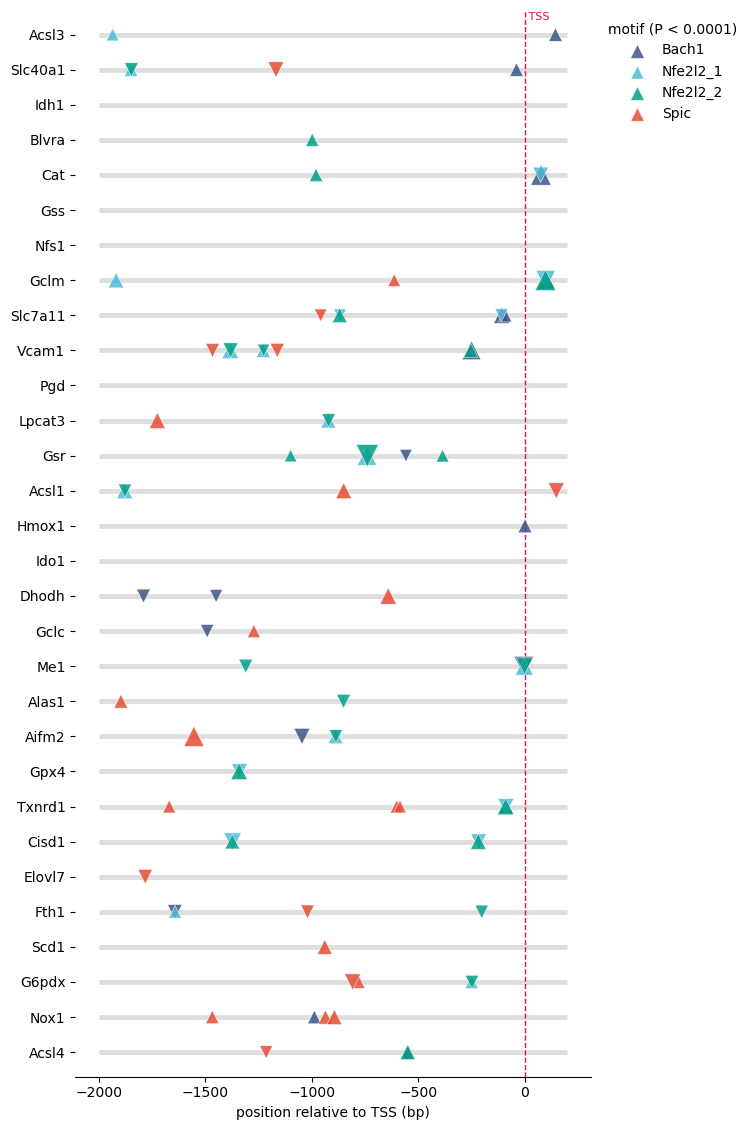

In [52]:
#| label: spicnetwork_alltfs_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Map"
#| output: asis

hits_SpiCnet_SpiCNfe2l2Bach1motif = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiCnetwork_SpiCNfe2l2Bach1motifs')             

graph_SpiCnet_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCnet_SpiCNfe2l2Bach1motif, name="SpiC_network_all_TFs")

In [53]:
#| label: spicnetwork_alltfs_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Table"
#| output: asis

spic_network_alltfs_motifs_table = process_motif_hits("SpiC_network_all_TFs", hits_SpiCnet_SpiCNfe2l2Bach1motif, gtf_sub)
spic_network_alltfs_motifs_table  

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promotor,end_motif_pos_promotor,Pval,sig,Chromosome,gene,Chromosome_Strand,TSS_chromossomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,GTGAGTCATCA,-1939,-1929,0.000091,4.039,NC_000067.7,Acsl3,+,78635600,-1929,78633661-78633671,+
1,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,0.000063,4.201,NC_000067.7,Acsl3,+,78635600,138,78635738-78635751,+
2,Slc40a1,NM_016917.2,GTGACTGAGCT,-1853,-1843,0.000068,4.164,NC_000067.7,Slc40a1,-,45964754,-1843,45966597-45966607,-
3,Slc40a1,NM_016917.2,CATAGCTCAGTCAC,-1853,-1840,0.000054,4.270,NC_000067.7,Slc40a1,-,45964754,-1840,45966594-45966607,+
4,Slc40a1,NM_016917.2,AAAATGGGGTAGTA,-1174,-1161,0.000020,4.694,NC_000067.7,Slc40a1,-,45964754,-1161,45965915-45965928,+
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,Nox1,NM_172203.2,TTAAAGAGGAACTT,-942,-929,0.000045,4.343,NC_000086.8,Nox1,-,133012603,-929,133013532-133013545,-
82,Nox1,NM_172203.2,TAAACGAGGAAGTC,-900,-887,0.000026,4.589,NC_000086.8,Nox1,-,133012603,-887,133013490-133013503,-
83,Acsl4,NM_207625.2,AAAAAGAAGAAGAA,-1220,-1207,0.000080,4.099,NC_000086.8,Acsl4,-,141173531,-1207,141174738-141174751,+
84,Acsl4,NM_207625.2,TTTTGCTGAGTGAC,-556,-543,0.000031,4.512,NC_000086.8,Acsl4,-,141173531,-543,141174074-141174087,-


# 5. Conclusion

This report established a reproducible workflow for extracting promoter sequences and mapping transcription-factor binding motifs in support of the SpiC regulatory analysis, working from the *Mus musculus* GRCm39 reference genome (Ensembl release 116) via `pyranges`.

Promoter regions were defined as −2,000 bp to +200 bp relative to the TSS of each canonical transcript and extracted in a strand-aware manner for two sets of genes: (i) the panel of SpiC-regulated candidate genes and (ii) the *Spic* / *Nfe2l2* pair used to probe direct cross-regulation. The resulting sequences were written to FASTA files, scanned for SpiC and Nfe2l2 motifs with RSAT, and the significant hits were translated from promoter-relative coordinates back to genomic coordinates to build publication-ready tables.

Detection of SpiC and Nfe2l2 motifs within these promoters provides preliminary, sequence-based evidence for potential direct regulatory interactions. Functional validation would be required to distinguish direct regulation from indirect, Nfe2l2-mediated regulation.


# **Session Information**

In [54]:
#| label: session_information
#| echo: false

## Report package versions and dependencies for reproducibility
print(session_info.show(html=False, dependencies=True))


-----
matplotlib          3.10.3
numpy               2.1.3
pandas              2.2.3
pyfaidx             0.9.0.4
pyranges            0.1.4
session_info        v1.0.1
-----
PIL                         11.2.1
anyio                       NA
arrow                       1.3.0
astroid                     3.3.9
asttokens                   NA
attr                        25.3.0
attrs                       25.3.0
babel                       2.17.0
brotli                      1.1.0
certifi                     2026.06.17
charset_normalizer          3.4.1
colorama                    0.4.6
comm                        0.2.2
cycler                      0.12.1
cython_runtime              NA
dateutil                    2.9.0.post0
debugpy                     1.8.14
decorator                   5.2.1
defusedxml                  0.7.1
executing                   2.1.0
fastjsonschema              NA
fqdn                        NA
idna                        3.10
ipykernel                   6.29.5
ipywidgets

/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [56]:
#| label: render_html
#| echo: false
#| output: false
#| message: false

##render html
os.system(f'quarto render "/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Notebooks/PromoterExtraction_adapted_with_rsatconda_refseqannotation.ipynb" --to html')


ERROR: Cell label names must be unique (found duplicate '#ft_crossregulation_motifs_table')

Stack trace:
    at file:///opt/quarto/bin/quarto.js:33115:15
    at jupyterToMarkdown (file:///opt/quarto/bin/quarto.js:35030:5)
    at eventLoopTick (ext:core/01_core.js:178:7)
    at async Object.execute (file:///opt/quarto/bin/quarto.js:77198:21)
    at async renderExecute (file:///opt/quarto/bin/quarto.js:123646:25)
    at async renderFileInternal (file:///opt/quarto/bin/quarto.js:123899:35)
    at async renderFiles (file:///opt/quarto/bin/quarto.js:123695:9)
    at async render (file:///opt/quarto/bin/quarto.js:129503:19)
    at async _Command.actionHandler (file:///opt/quarto/bin/quarto.js:129745:24)
    at async _Command.execute (file:///opt/quarto/bin/quarto.js:9840:7)


256